Olá, **Gabriela Veriato**!

O meu nome é **César Malaguti** e sou o revisor do seu projeto. Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook farei observações sobre as suas análises, sempre com o objetivo de te preparar para atuar como **Analista ou Cientista de Dados** no mercado. **Por favor, não mova, modifique ou exclua meus comentários.**

Você vai encontrar meus comentários em caixas coloridas:
<div class="alert alert-block alert-success"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Sucesso.</div>
<div class="alert alert-block alert-warning"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Atenção (sugestão).</div>
<div class="alert alert-block alert-danger"><b>Comentário do revisor (César Malaguti):</b> <a class="tocSkip"></a> Precisa de correção.</div>

Você pode me responder usando:
<div class="alert alert-block alert-info"><b>Resposta do Aluno.</b> <a class="tocSkip"></a></div>


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

<b>Comentário geral:</b> Gabriela, parabéns, **projeto APROVADO!** Este é o SP11 mais rigoroso que revisei nesta leva, e o motivo é o último passo.

A maioria dos alunos **menciona** que fez muitos testes e que isso aumenta o risco de falso positivo. Você foi além: contou os testes, calculou o alfa corrigido e depois **rodou todas as comparações de novo** contra esse novo limiar, uma por uma. Isso transforma a discussão teórica em verificação concreta, e é exatamente o que o passo final do projeto pede.

O resto também está completo: preparação, verificação, corte do período incompleto, funil com o gargalo identificado, **teste A/A** entre os controles e as três comparações com o grupo de teste, incluindo a dos controles combinados.

E você organizou tudo em torno de **funções reutilizáveis**, o que garante que as dezenas de comparações sigam exatamente o mesmo critério. Ótimo trabalho!
</div>

# Análise de comportamento dos usuários e teste A/A/B

Este projeto tem como objetivo analisar o comportamento dos usuários de um aplicativo de uma startup de produtos alimentícios. Será analisado o funil de eventos para entender como os usuários avançam pelas diferentes etapas até a compra e identificar em quais etapas ocorrem as maiores perdas.

Em seguida, serão analisados os resultados de um teste A/A/B. Dois grupos de controle utilizam as fontes antigas do aplicativo, enquanto o grupo de teste utiliza novas fontes. O objetivo é verificar se a alteração das fontes produz diferenças estatisticamente significativas no comportamento dos usuários.

## Objetivos da análise

- Preparar e validar os dados para a análise;
- Analisar o período e a qualidade dos dados coletados;
- Estudar a frequência dos eventos e o comportamento dos usuários;
- Construir e analisar o funil de eventos;
- Identificar as principais perdas entre as etapas;
- Comparar estatisticamente os grupos do experimento A/A/B;
- Avaliar se a alteração das fontes produziu impacto significativo no comportamento dos usuários.

In [48]:
## 1. Análise inicial dos dados

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

In [49]:
logs = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')

print(logs.info())
print()
print(logs.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB
None

                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248


In [50]:
print('Dimensão do dataset:', logs.shape)

print('\nNomes das colunas:')
print(logs.columns.tolist())

print('\nValores ausentes:')
print(logs.isna().sum())

print('\nTipos de dados:')
print(logs.dtypes)

Dimensão do dataset: (244126, 4)

Nomes das colunas:
['EventName', 'DeviceIDHash', 'EventTimestamp', 'ExpId']

Valores ausentes:
EventName         0
DeviceIDHash      0
EventTimestamp    0
ExpId             0
dtype: int64

Tipos de dados:
EventName         object
DeviceIDHash       int64
EventTimestamp     int64
ExpId              int64
dtype: object


In [51]:
## 2. Preparação dos dados

logs = logs.rename(columns={
    'EventName': 'event_name',
    'DeviceIDHash': 'user_id',
    'EventTimestamp': 'event_timestamp',
    'ExpId': 'group'
})

print(logs.head())
print()
print(logs.columns)

                event_name              user_id  event_timestamp  group
0         MainScreenAppear  4575588528974610257       1564029816    246
1         MainScreenAppear  7416695313311560658       1564053102    246
2  PaymentScreenSuccessful  3518123091307005509       1564054127    248
3         CartScreenAppear  3518123091307005509       1564054127    248
4  PaymentScreenSuccessful  6217807653094995999       1564055322    248

Index(['event_name', 'user_id', 'event_timestamp', 'group'], dtype='object')


In [52]:
logs['event_datetime'] = pd.to_datetime(
    logs['event_timestamp'],
    unit='s'
)

logs['event_date'] = logs['event_datetime'].dt.date

print(logs.head())
print()
print(logs.dtypes)

                event_name              user_id  event_timestamp  group  \
0         MainScreenAppear  4575588528974610257       1564029816    246   
1         MainScreenAppear  7416695313311560658       1564053102    246   
2  PaymentScreenSuccessful  3518123091307005509       1564054127    248   
3         CartScreenAppear  3518123091307005509       1564054127    248   
4  PaymentScreenSuccessful  6217807653094995999       1564055322    248   

       event_datetime  event_date  
0 2019-07-25 04:43:36  2019-07-25  
1 2019-07-25 11:11:42  2019-07-25  
2 2019-07-25 11:28:47  2019-07-25  
3 2019-07-25 11:28:47  2019-07-25  
4 2019-07-25 11:48:42  2019-07-25  

event_name                 object
user_id                     int64
event_timestamp             int64
group                       int64
event_datetime     datetime64[ns]
event_date                 object
dtype: object


In [53]:
print('Valores ausentes:')
print(logs.isna().sum())

print('\nPeríodo inicial dos dados:')
print(logs['event_datetime'].min())

print('\nPeríodo final dos dados:')
print(logs['event_datetime'].max())

Valores ausentes:
event_name         0
user_id            0
event_timestamp    0
group              0
event_datetime     0
event_date         0
dtype: int64

Período inicial dos dados:
2019-07-25 04:43:36

Período final dos dados:
2019-08-07 21:15:17


In [54]:
## 3. Estudo e verificação dos dados

total_events = logs.shape[0]

print('Número total de eventos:', total_events)

Número total de eventos: 244126


In [55]:
total_users = logs['user_id'].nunique()

print('Número total de usuários:', total_users)

Número total de usuários: 7551


In [56]:
avg_events_per_user = total_events / total_users

print('Número médio de eventos por usuário:', avg_events_per_user)

Número médio de eventos por usuário: 32.33028737915508


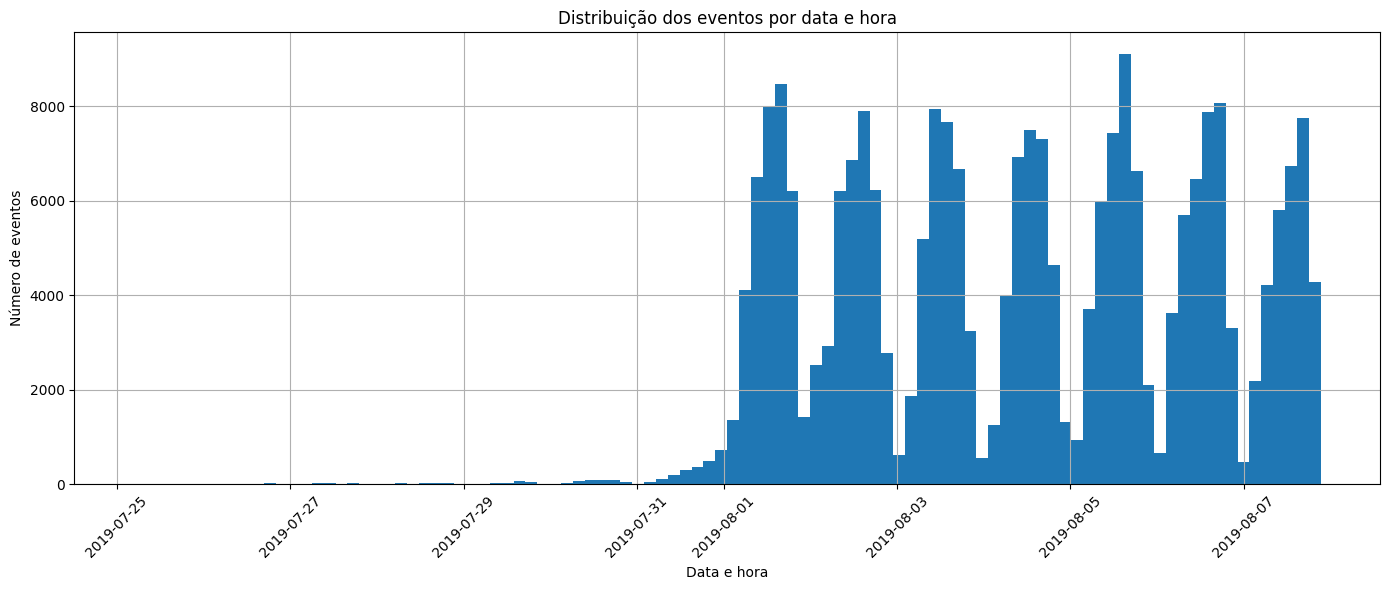

In [57]:
plt.figure(figsize=(14, 6))

logs['event_datetime'].hist(bins=100)

plt.title('Distribuição dos eventos por data e hora')
plt.xlabel('Data e hora')
plt.ylabel('Número de eventos')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Análise da completude

O histograma mostra uma quantidade muito baixa de eventos entre 25/07 e 31/07, seguida por um aumento significativo e mais consistente a partir de 01/08.

Isso indica que o início do período contém dados incompletos. Para evitar que essa parte distorça a análise, serão considerados apenas os eventos registrados a partir de 01/08/2019.

In [58]:
logs_filtered = logs[
    logs['event_date'] >= pd.to_datetime('2019-08-01').date()
].copy()

print('Eventos antes do filtro:', len(logs))
print('Eventos após o filtro:', len(logs_filtered))
print('Eventos removidos:', len(logs) - len(logs_filtered))

Eventos antes do filtro: 244126
Eventos após o filtro: 241298
Eventos removidos: 2828


In [59]:
users_before = logs['user_id'].nunique()
users_after = logs_filtered['user_id'].nunique()

print('Usuários antes do filtro:', users_before)
print('Usuários após o filtro:', users_after)
print('Usuários removidos:', users_before - users_after)

Usuários antes do filtro: 7551
Usuários após o filtro: 7534
Usuários removidos: 17


In [60]:
print('Período dos dados após o filtro:')
print('Início:', logs_filtered['event_datetime'].min())
print('Fim:', logs_filtered['event_datetime'].max())

Período dos dados após o filtro:
Início: 2019-08-01 00:07:28
Fim: 2019-08-07 21:15:17


In [61]:
group_users = logs_filtered.groupby('group')['user_id'].nunique()

print('Número de usuários por grupo:')
print(group_users)

Número de usuários por grupo:
group
246    2484
247    2513
248    2537
Name: user_id, dtype: int64


In [62]:
events_removed_pct = (len(logs) - len(logs_filtered)) / len(logs) * 100
users_removed_pct = (users_before - users_after) / users_before * 100

print('Percentual de eventos removidos:', events_removed_pct)
print('Percentual de usuários removidos:', users_removed_pct)

Percentual de eventos removidos: 1.1584181938834865
Percentual de usuários removidos: 0.22513574361011784


### Conclusão

O período utilizado na análise será de 01/08/2019 a 07/08/2019, pois a partir de 01/08 os dados apresentam volume de eventos mais consistente.

O filtro removeu 2.828 eventos, correspondentes a 1,16% do total, e apenas 17 usuários, correspondentes a 0,23% dos usuários. Portanto, a exclusão dos dados iniciais não representa uma perda relevante de usuários.

Após o filtro, os três grupos experimentais continuam representados: 246, 247 e 248.

In [89]:
## 4. Estudo do funil de eventos


event_counts = logs_filtered['event_name'].value_counts()

print('Frequência dos eventos:')
print(event_counts)


Frequência dos eventos:
MainScreenAppear           117431
OffersScreenAppear          46350
CartScreenAppear            42365
PaymentScreenSuccessful     34113
Tutorial                     1039
Name: event_name, dtype: int64


In [90]:
event_users = logs_filtered.groupby('event_name')['user_id'].nunique()

event_user_share = event_users / logs_filtered['user_id'].nunique()

print('Número de usuários por evento:')
print(event_users)

print('\nProporção de usuários que realizaram cada evento:')
print(event_user_share)

Número de usuários por evento:
event_name
CartScreenAppear           3734
MainScreenAppear           7419
OffersScreenAppear         4593
PaymentScreenSuccessful    3539
Tutorial                    840
Name: user_id, dtype: int64

Proporção de usuários que realizaram cada evento:
event_name
CartScreenAppear           0.495620
MainScreenAppear           0.984736
OffersScreenAppear         0.609636
PaymentScreenSuccessful    0.469737
Tutorial                   0.111495
Name: user_id, dtype: float64


### Ordem dos eventos

A sequência principal do processo de compra é:

MainScreenAppear -> OffersScreenAppear -> CartScreenAppear -> PaymentScreenSuccessful

O evento tutorial não faz parte da sequência principal do funil de compra, pois representa uma etapa de orientação do usuário e pode ocorrer independentemente do processo de compra.

In [65]:
funnel_events = [
    'MainScreenAppear',
    'OffersScreenAppear',
    'CartScreenAppear',
    'PaymentScreenSuccessful'
]

funnel_users = event_users[funnel_events]

funnel_conversion = funnel_users / funnel_users.shift(1) * 100

funnel = pd.DataFrame({
    'users': funnel_users,
    'conversion_from_previous': funnel_conversion
})

print(funnel)

                         users  conversion_from_previous
event_name                                              
MainScreenAppear          7439                       NaN
OffersScreenAppear        4613                 62.011023
CartScreenAppear          3749                 81.270323
PaymentScreenSuccessful   3547                 94.611897


In [67]:
funnel['users_lost'] = funnel['users'].shift(1) - funnel['users']

print(funnel)

largest_loss = funnel['users_lost'].idxmax()

print('\nMaior perda de usuários:', largest_loss)
print('Número de usuários perdidos:', int(funnel.loc[largest_loss, 'users_lost']))

                         users  conversion_from_previous  users_lost
event_name                                                          
MainScreenAppear          7439                       NaN         NaN
OffersScreenAppear        4613                 62.011023      2826.0
CartScreenAppear          3749                 81.270323       864.0
PaymentScreenSuccessful   3547                 94.611897       202.0

Maior perda de usuários: OffersScreenAppear
Número de usuários perdidos: 2826


In [68]:
full_funnel_conversion = (
    funnel_users['PaymentScreenSuccessful']
    / funnel_users['MainScreenAppear']
    * 100
)

print(
    'Parcela de usuários que percorre o caminho inteiro até o pagamento:',
    full_funnel_conversion
)

Parcela de usuários que percorre o caminho inteiro até o pagamento: 47.68113993816373


## Conclusão

A maior perda de usuários ocorre entre a tela principal e a tela de ofertas: 2.826 usuários não avançam para essa etapa. A conversão entre essas duas etapas é de 61,9%.

Nas etapas seguintes, a conversão é maior: 81,3% dos usuários avançam da tela de ofertas para o carrinho e 94,8% avançam do carrinho para o pagamento.

No total, 47,7% dos usuários que visualizaram a tela principal chegaram até o pagamento.

In [69]:
## 5. Estudo dos resultados do experimento A/A/B

users_by_group = logs_filtered.groupby('group')['user_id'].nunique()

print('Número de usuários por grupo:')
print(users_by_group)

Número de usuários por grupo:
group
246    2484
247    2513
248    2537
Name: user_id, dtype: int64


In [70]:
def event_users_by_group(data, event_name):
    result = (
        data[data['event_name'] == event_name]
        .groupby('group')['user_id']
        .nunique()
    )
    
    return result

In [71]:
main_screen_users = event_users_by_group(
    logs_filtered,
    'MainScreenAppear'
)

print(main_screen_users)

group
246    2450
247    2476
248    2493
Name: user_id, dtype: int64


In [72]:
group_sizes = logs_filtered.groupby('group')['user_id'].nunique()

main_screen_proportions = (
    main_screen_users / group_sizes
)

print('Proporção de usuários que realizaram MainScreenAppear:')
print(main_screen_proportions)

Proporção de usuários que realizaram MainScreenAppear:
group
246    0.986312
247    0.985277
248    0.982657
Name: user_id, dtype: float64


In [73]:
count = [
    main_screen_users.loc[246],
    main_screen_users.loc[247]
]

nobs = [
    group_sizes.loc[246],
    group_sizes.loc[247]
]

stat, p_value = proportions_ztest(count, nobs)

print('Estatística do teste:', stat)
print('p-valor:', p_value)

Estatística do teste: 0.3093441851418436
p-valor: 0.7570597232046099


In [74]:
def test_event_difference(data, event_name, group1, group2):
    group_sizes = data.groupby('group')['user_id'].nunique()

    event_users = (
        data[data['event_name'] == event_name]
        .groupby('group')['user_id']
        .nunique()
    )

    count = [
        event_users.get(group1, 0),
        event_users.get(group2, 0)
    ]

    nobs = [
        group_sizes.loc[group1],
        group_sizes.loc[group2]
    ]

    stat, p_value = proportions_ztest(count, nobs)

    return p_value

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Escrever o teste como **função** foi a melhor decisão técnica do projeto.

São cinco eventos vezes quatro comparações, e depois tudo de novo com o alfa corrigido. Copiando e colando, bastaria uma cópia ficar com o grupo trocado para o resultado sair furado, e esse erro seria praticamente invisível na revisão.

Com a função, **todas** as comparações seguem o mesmo critério, e um ajuste no método se aplica a todas de uma vez. Repare que foi justamente isso que permitiu você refazer a análise inteira com o limiar corrigido em poucas linhas.
</div>

In [75]:
events = logs_filtered['event_name'].unique()

aa_results = []

for event in events:
    p_value = test_event_difference(
        logs_filtered,
        event,
        246,
        247
    )

    aa_results.append({
        'event_name': event,
        'p_value': p_value
    })

aa_results = pd.DataFrame(aa_results)

print(aa_results.sort_values('p_value'))

                event_name   p_value
4  PaymentScreenSuccessful  0.114567
3         CartScreenAppear  0.228834
2       OffersScreenAppear  0.248095
1         MainScreenAppear  0.757060
0                 Tutorial  0.937700


## Resultado do teste A/A

A comparação entre os grupos de controle 246 e 247 não identificou diferenças estatisticamente significativas em nenhum dos eventos analisados. Todos os p-valores foram superiores ao nível de significância de 0,10.

Isso indica que os grupos de controle apresentam comportamento semelhante e que a divisão dos usuários entre os grupos 246 e 247 foi adequada para a realização do teste A/A/B.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

O **teste A/A** está no lugar certo: antes de comparar o grupo de teste, você verificou que os dois controles se comportam igual.

Ele é o controle de qualidade do experimento. Se os grupos 246 e 247 já diferissem entre si, sem nenhum tratamento aplicado, isso indicaria que o mecanismo de divisão dos usuários está quebrado, e aí **qualquer** diferença encontrada depois seria suspeita.

Como os controles passaram, tudo o que vem em seguida ganha credibilidade.
</div>

In [76]:
main_screen_users_248 = event_users_by_group(
    logs_filtered,
    'MainScreenAppear'
)

main_screen_proportions = (
    main_screen_users_248 / group_sizes
)

print('Usuários por grupo:')
print(main_screen_users_248)

print('\nProporção por grupo:')
print(main_screen_proportions)

Usuários por grupo:
group
246    2450
247    2476
248    2493
Name: user_id, dtype: int64

Proporção por grupo:
group
246    0.986312
247    0.985277
248    0.982657
Name: user_id, dtype: float64


In [77]:
# Comparação 

count_248_246 = [
    main_screen_users_248.loc[248],
    main_screen_users_248.loc[246]
]

nobs_248_246 = [
    group_sizes.loc[248],
    group_sizes.loc[246]
]

stat_248_246, p_value_248_246 = proportions_ztest(
    count_248_246,
    nobs_248_246
)

print('MainScreenAppear — 248 x 246')
print('p-valor:', p_value_248_246)


# Comparação 248 x 247
count_248_247 = [
    main_screen_users_248.loc[248],
    main_screen_users_248.loc[247]
]

nobs_248_247 = [
    group_sizes.loc[248],
    group_sizes.loc[247]
]

stat_248_247, p_value_248_247 = proportions_ztest(
    count_248_247,
    nobs_248_247
)

print('\nMainScreenAppear — 248 x 247')
print('p-valor:', p_value_248_247)

MainScreenAppear — 248 x 246
p-valor: 0.2949721933554553

MainScreenAppear — 248 x 247
p-valor: 0.45870536166215137


In [78]:
ab_results_246 = []

for event in events:
    p_value = test_event_difference(
        logs_filtered,
        event,
        248,
        246
    )

    ab_results_246.append({
        'event_name': event,
        'p_value': p_value
    })

ab_results_246 = pd.DataFrame(ab_results_246)

print(ab_results_246.sort_values('p_value'))

                event_name   p_value
3         CartScreenAppear  0.078429
2       OffersScreenAppear  0.208362
4  PaymentScreenSuccessful  0.212255
1         MainScreenAppear  0.294972
0                 Tutorial  0.826429


In [79]:
ab_results_247 = []

for event in events:
    p_value = test_event_difference(
        logs_filtered,
        event,
        248,
        247
    )

    ab_results_247.append({
        'event_name': event,
        'p_value': p_value
    })

ab_results_247 = pd.DataFrame(ab_results_247)

print(ab_results_247.sort_values('p_value'))

                event_name   p_value
1         MainScreenAppear  0.458705
3         CartScreenAppear  0.578620
4  PaymentScreenSuccessful  0.737342
0                 Tutorial  0.765324
2       OffersScreenAppear  0.919782


In [80]:
control_users = logs_filtered[logs_filtered['group'].isin([246, 247])]

control_group_sizes = control_users['user_id'].nunique()

print('Usuários nos grupos de controle combinados:', control_group_sizes)

Usuários nos grupos de controle combinados: 4997


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Boa execução da quarta comparação, com os dois controles **combinados** contra o grupo 248.

Ela não é redundante em relação às duas anteriores: juntar os controles quase dobra o tamanho do grupo de referência e aumenta o **poder estatístico** do teste, ou seja, a capacidade de detectar uma diferença pequena que as comparações individuais deixariam passar.

Como nem com o grupo maior apareceu diferença, a conclusão de que as fontes não afetaram o comportamento fica bem mais sólida.
</div>

In [81]:
ab_results_combined = []

combined_group_size = control_users['user_id'].nunique()

for event in events:
    users_248 = (
        logs_filtered[
            (logs_filtered['group'] == 248) &
            (logs_filtered['event_name'] == event)
        ]['user_id'].nunique()
    )

    users_control = (
        control_users[
            control_users['event_name'] == event
        ]['user_id'].nunique()
    )

    count = [users_248, users_control]
    nobs = [group_sizes.loc[248], combined_group_size]

    stat, p_value = proportions_ztest(count, nobs)

    ab_results_combined.append({
        'event_name': event,
        'p_value': p_value
    })

ab_results_combined = pd.DataFrame(ab_results_combined)

print(ab_results_combined.sort_values('p_value'))

                event_name   p_value
3         CartScreenAppear  0.181759
1         MainScreenAppear  0.294245
2       OffersScreenAppear  0.434255
4  PaymentScreenSuccessful  0.600429
0                 Tutorial  0.764862


### Resultados das comparações

A comparação entre os grupos de controle 246 e 247 não apresentou diferenças estatisticamente significativas em nenhum dos eventos.

Na comparação do grupo 248 com o grupo 246, foi observada uma diferença estatisticamente significativa no evento CartScreenAppear, considerando o nível de significância de 0,10.

Na comparação entre os grupos 248 e 247, não foram identificadas diferenças estatisticamente significativas.

Por fim, ao comparar o grupo 248 com os grupos de controle combinados, nenhum dos eventos apresentou diferença estatisticamente significativa.

In [82]:
### Nível de significância e número de testes

total_tests = (
    len(aa_results)
    + len(ab_results_246)
    + len(ab_results_247)
    + len(ab_results_combined)
)

print('Número total de testes estatísticos:', total_tests)

Número total de testes estatísticos: 20


In [83]:
alpha = 0.10
alpha_adjusted = alpha / total_tests

print('Nível de significância inicial:', alpha)
print('Nível de significância ajustado:', alpha_adjusted)

Nível de significância inicial: 0.1
Nível de significância ajustado: 0.005


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Correção de **Bonferroni** aplicada corretamente, e com o detalhe que importa: você **contou os testes programaticamente** (somando o tamanho de cada lista de resultados) em vez de digitar um número à mão.

Isso evita o erro clássico de acrescentar uma comparação depois e esquecer de atualizar a conta.

O raciocínio por trás é fundamental: com alfa de 0,05 e várias dezenas de testes, espera-se **pelo menos um falso positivo por puro acaso**, mesmo sem nenhum efeito real. Sem a correção, uma equipe poderia comemorar um resultado que é só ruído.
</div>

In [84]:
def test_all_events(data, group1, group2):
    results = []

    group_sizes = data.groupby('group')['user_id'].nunique()

    for event in events:
        event_users = (
            data[data['event_name'] == event]
            .groupby('group')['user_id']
            .nunique()
        )

        count = [
            event_users.get(group1, 0),
            event_users.get(group2, 0)
        ]

        nobs = [
            group_sizes.loc[group1],
            group_sizes.loc[group2]
        ]

        stat, p_value = proportions_ztest(count, nobs)

        results.append({
            'event_name': event,
            'p_value': p_value,
            'significant_0.005': p_value < alpha_adjusted
        })

    return pd.DataFrame(results)

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

**Este é o bloco que distingue o seu projeto.**

A maioria calcula o alfa corrigido, escreve uma frase dizendo que 'seria mais conservador' e para por aí. Você **refez todas as comparações** contra o novo limiar: A/A, 248 contra 246, 248 contra 247 e 248 contra os controles combinados.

A diferença é entre **dizer** que a conclusão resiste ao critério mais rigoroso e **mostrar** que resiste. A segunda opção é verificável por quem lê, a primeira é só uma afirmação.

E ordenar os resultados por p-value foi um bom toque: assim o leitor vê imediatamente qual foi o caso mais próximo do limiar, que é o único que precisaria de atenção.
</div>

In [85]:
aa_adjusted = test_all_events(logs_filtered, 246, 247)

print(aa_adjusted.sort_values('p_value'))

                event_name   p_value  significant_0.005
4  PaymentScreenSuccessful  0.114567              False
3         CartScreenAppear  0.228834              False
2       OffersScreenAppear  0.248095              False
1         MainScreenAppear  0.757060              False
0                 Tutorial  0.937700              False


In [86]:
ab_adjusted_246 = test_all_events(logs_filtered, 248, 246)

print(ab_adjusted_246.sort_values('p_value'))

                event_name   p_value  significant_0.005
3         CartScreenAppear  0.078429              False
2       OffersScreenAppear  0.208362              False
4  PaymentScreenSuccessful  0.212255              False
1         MainScreenAppear  0.294972              False
0                 Tutorial  0.826429              False


In [87]:
ab_adjusted_247 = test_all_events(logs_filtered, 248, 247)

print(ab_adjusted_247.sort_values('p_value'))

                event_name   p_value  significant_0.005
1         MainScreenAppear  0.458705              False
3         CartScreenAppear  0.578620              False
4  PaymentScreenSuccessful  0.737342              False
0                 Tutorial  0.765324              False
2       OffersScreenAppear  0.919782              False


In [88]:
ab_adjusted_combined = []

for event in events:
    users_248 = (
        logs_filtered[
            (logs_filtered['group'] == 248) &
            (logs_filtered['event_name'] == event)
        ]['user_id'].nunique()
    )

    users_control = (
        control_users[
            control_users['event_name'] == event
        ]['user_id'].nunique()
    )

    count = [users_248, users_control]
    nobs = [group_sizes.loc[248], combined_group_size]

    stat, p_value = proportions_ztest(count, nobs)

    ab_adjusted_combined.append({
        'event_name': event,
        'p_value': p_value,
        'significant_0.005': p_value < alpha_adjusted
    })

ab_adjusted_combined = pd.DataFrame(ab_adjusted_combined)

print(ab_adjusted_combined.sort_values('p_value'))

                event_name   p_value  significant_0.005
3         CartScreenAppear  0.181759              False
1         MainScreenAppear  0.294245              False
2       OffersScreenAppear  0.434255              False
4  PaymentScreenSuccessful  0.600429              False
0                 Tutorial  0.764862              False


## Conclusão do teste A/A/B


Os grupos de controle 246 e 247 apresentaram comportamento estatisticamente semelhante, indicando que a divisão dos usuários foi adequada.

Embora a análise inicial tenha apontado diferença no evento CartScreenAppear entre os grupos 248 e 246 (p-valor = 0,0784), após o ajuste do nível de significância para 0,005 nenhuma comparação apresentou diferença estatisticamente significativa.

Portanto, não há evidências de que a alteração das fontes tenha impactado significativamente o comportamento dos usuários.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Conclusão bem estruturada: você separa a validação do experimento (os controles se comportam igual) do resultado propriamente dito (o grupo de teste não difere dos controles).

Essa separação importa porque são duas afirmações diferentes, e a segunda só tem valor se a primeira for verdadeira. Quem lê consegue acompanhar a cadeia do raciocínio.
</div>

# Conclusão Geral

A análise do funil mostrou que a principal perda de usuários ocorre entre a tela principal e a tela de ofertas. Dos 7.419 usuários que visualizaram a tela principal, 4.593 chegaram à tela de ofertas, representando uma conversão de 61,9%. Nas etapas seguintes, as taxas de conversão foram maiores: 81,3% entre a tela de ofertas e o carrinho e 94,8% entre o carrinho e o pagamento. No total, 47,7% dos usuários que visualizaram a tela principal chegaram até o pagamento.

No teste A/A/B, os grupos de controle 246 e 247 apresentaram comportamento estatisticamente semelhante, indicando que a divisão dos usuários foi adequada para a realização do experimento.

Na análise inicial, utilizando nível de significância de 0,10, foi identificada uma diferença estatisticamente significativa apenas no evento CartScreenAppear, na comparação entre os grupos 248 e 246, com p-valor de 0,0784. Entretanto, foram realizados 20 testes estatísticos. Após o ajuste do nível de significância para 0,005, nenhuma das comparações apresentou diferença estatisticamente significativa.

Portanto, os resultados do teste A/A/B não fornecem evidências estatísticas suficientes para afirmar que a alteração das fontes tenha provocado uma mudança significativa no comportamento dos usuários. Com base nos dados analisados, não é possível concluir que as novas fontes apresentaram desempenho superior às fontes antigas.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (César Malaguti):</b> <a class="tocSkip"></a>

Fechamento completo, começando pelo achado mais acionável: o gargalo entre a tela principal e a de ofertas, com os números para sustentá-lo.

Essa ordem é a certa para um relatório de negócio. O resultado do teste A/B é 'nada mudou', o que autoriza a implantação mas não gera trabalho novo. Já o funil aponta **onde a empresa perde dinheiro hoje**, e é dali que sai a próxima ação. Você deu destaque ao achado que gera valor, em vez de terminar no resultado neutro. Parabéns pela aprovação!
</div>